# Handle missing value
## iterativeimputer
## simpleimputer

# Missing values handeling

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

In [2]:
df_air = pd.read_csv('../../data/air-quality.csv', parse_dates = ['Date'],index_col='Date')

In [3]:
df_air.head()

,Ozone,Solar.R,Wind,Temp
Date,,,,
1973-05-01,41.0,190.0,7.4,67
1973-05-02,36.0,118.0,8.0,72
1973-05-03,12.0,149.0,12.6,74
1973-05-04,18.0,313.0,11.5,62
1973-05-05,NaN,NaN,14.3,56


In [4]:
nullity_df = df_air.isnull().sum().to_frame(name = 'Missing Values')

In [5]:
nullity_df['%Missing'] = (df_air.isnull().mean()*100).round(1)

In [6]:
nullity_df

,Missing Values,%Missing
Ozone,37,24.2
Solar.R,7,4.6
Wind,0,0.0
Temp,0,0.0


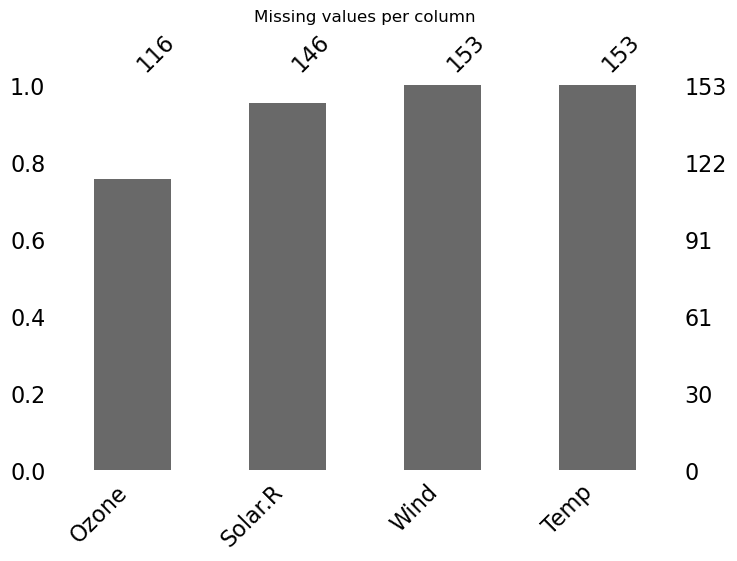

In [7]:
msno.bar(df_air, figsize=(8,5))
plt.title("Missing values per column")
plt.show()


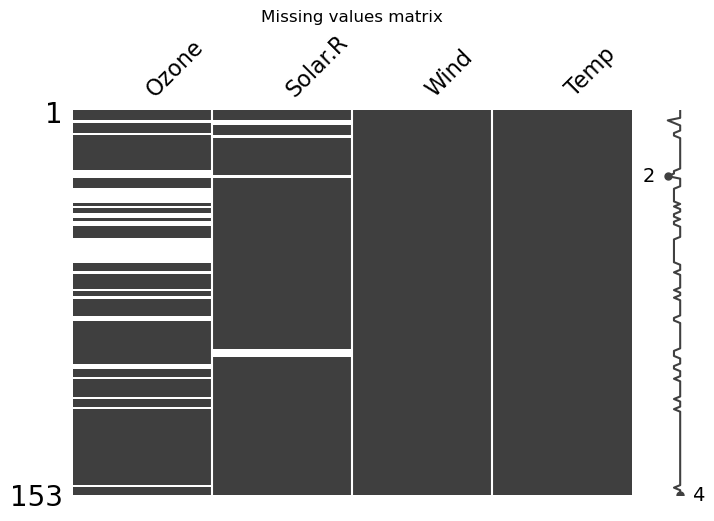

In [8]:
msno.matrix(df_air, figsize=(8,5))
plt.title("Missing values matrix")
plt.show()


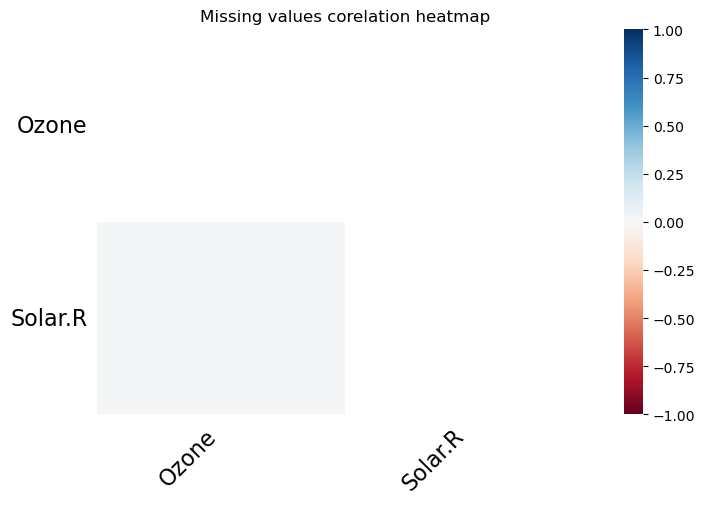

In [9]:
msno.heatmap(df_air, figsize=(8,5))
plt.title("Missing values corelation heatmap")
plt.show()

# Feature engineering

In [10]:
# each column is called a feature in data science
# All coulmns are know while one coulmn is predicted
# target is also called Label also
# Input feactures vs target features
# manipulation of input feachers 
# goal is to clean data so that our target is accurate as much as possible

In [11]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [12]:
df.shape

(178, 14)

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
X_train.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
158,14.34,1.68,2.70,25.0,98.0,2.80,1.31,0.53,2.70,13.00,0.57,1.96,660.0
137,12.53,5.51,2.64,25.0,96.0,1.79,0.60,0.63,1.10,5.00,0.82,1.69,515.0
98,12.37,1.07,2.10,18.5,88.0,3.52,3.75,0.24,1.95,4.50,1.04,2.77,660.0
159,13.48,1.67,2.64,22.5,89.0,2.60,1.10,0.52,2.29,11.75,0.57,1.78,620.0
38,13.07,1.50,2.10,15.5,98.0,2.40,2.64,0.28,1.37,3.70,1.18,2.69,1020.0


In [15]:
y_train.head()

158    2
137    2
98     1
159    2
38     0
Name: target, dtype: int32

In [16]:
X_train.shape

(142, 13)

In [17]:
X_test.shape

(36, 13)

# Standardization and Normalization

In [18]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
X_train_scaled

array([[ 1.66529275, -0.60840587,  1.21896194, ..., -1.65632857,
        -0.87940904, -0.24860607],
       [-0.54952506,  2.7515415 ,  1.00331502, ..., -0.58463272,
        -1.25462095, -0.72992237],
       [-0.74531007, -1.14354109, -0.93750727, ...,  0.35845962,
         0.2462267 , -0.24860607],
       ...,
       [ 1.714239  , -0.44172441,  0.06884503, ...,  1.04434496,
         0.56585166,  2.69572196],
       [-0.35374006, -0.7399965 , -0.36244882, ...,  0.01551695,
        -0.74044166, -0.79631083],
       [-0.78201975,  0.06709269,  0.35637426, ..., -0.67036839,
         1.09392769, -0.98551793]])

In [20]:
from sklearn.preprocessing import Normalizer

normalizer = Normalizer()
X_train_norm = normalizer.fit_transform(X_train_scaled)
X_test_norm = normalizer.transform(X_test_scaled)

In [21]:
X_test_norm

array([[ 2.63761110e-01,  2.07855770e-01,  2.33447092e-01,
        -4.04832414e-01,  3.47525156e-01,  2.10894735e-01,
         3.35025851e-01, -5.05297077e-01,  2.91441323e-02,
         5.95279985e-03,  5.06071299e-03,  3.47710077e-01,
         1.19200344e-01],
       [ 4.91191475e-01,  4.76756543e-01,  9.27754625e-02,
        -5.43015047e-02,  2.35803321e-01,  2.87851443e-01,
         2.11149494e-01, -1.73566677e-01, -2.00751160e-01,
         2.56083918e-02, -1.20756162e-01,  3.34080689e-01,
         3.73574971e-01],
       [-1.86398560e-02,  1.18832604e-01,  3.78293458e-01,
         1.37632904e-01, -9.44611394e-02, -3.65828323e-01,
        -4.65874145e-01,  3.93271609e-01, -4.57844443e-01,
        -6.11417388e-02, -2.47953468e-01, -1.21971088e-01,
        -1.38961684e-01],
       [ 2.54128735e-01, -2.11938761e-01,  3.37126912e-01,
         2.43161043e-01,  1.05393907e-02,  3.09406249e-01,
         3.44910219e-01, -1.68837577e-01,  3.67098361e-01,
         7.64914225e-02,  2.76977384e

### Random forest classifier for identifying importent features which contribute most in predicting

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [23]:
from sklearn.feature_selection import SelectFromModel

selector = SelectFromModel(rf, threshold="median")
X_train_selected  = selector.transform(X_train_scaled)
X_test_selected = selector.transform(X_test_scaled)

In [24]:
X_train_scaled

array([[ 1.66529275, -0.60840587,  1.21896194, ..., -1.65632857,
        -0.87940904, -0.24860607],
       [-0.54952506,  2.7515415 ,  1.00331502, ..., -0.58463272,
        -1.25462095, -0.72992237],
       [-0.74531007, -1.14354109, -0.93750727, ...,  0.35845962,
         0.2462267 , -0.24860607],
       ...,
       [ 1.714239  , -0.44172441,  0.06884503, ...,  1.04434496,
         0.56585166,  2.69572196],
       [-0.35374006, -0.7399965 , -0.36244882, ...,  0.01551695,
        -0.74044166, -0.79631083],
       [-0.78201975,  0.06709269,  0.35637426, ..., -0.67036839,
         1.09392769, -0.98551793]])

In [25]:
features_bool = selector.get_support()
selected_features = X.columns[features_bool]

In [26]:
X_train[selected_features].head()

,alcohol,magnesium,flavanoids,color_intensity,hue,od280/od315_of_diluted_wines,proline
158,14.34,98.0,1.31,13.00,0.57,1.96,660.0
137,12.53,96.0,0.60,5.00,0.82,1.69,515.0
98,12.37,88.0,3.75,4.50,1.04,2.77,660.0
159,13.48,89.0,1.10,11.75,0.57,1.78,620.0
38,13.07,98.0,2.64,3.70,1.18,2.69,1020.0


# Outlier Detection/Analysis

## Histogram plot

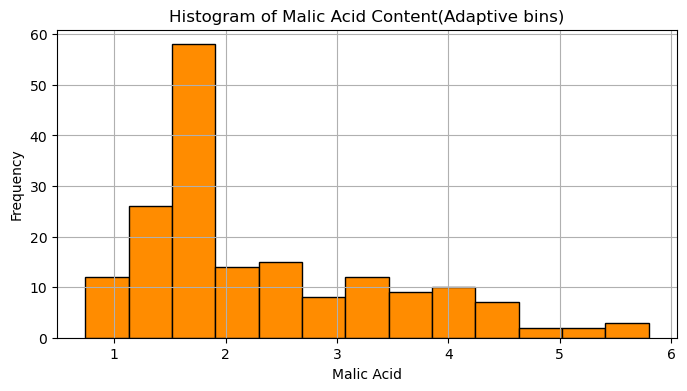

In [27]:
import matplotlib.pyplot

macid = df['malic_acid']
n_bins = int(np.sqrt(len(macid)))

plt.figure(figsize=(8,4))
plt.hist(macid, bins=n_bins, color= 'darkorange', edgecolor = 'black')
plt.title('Histogram of Malic Acid Content(Adaptive bins)')
plt.xlabel('Malic Acid')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

## scatter plot

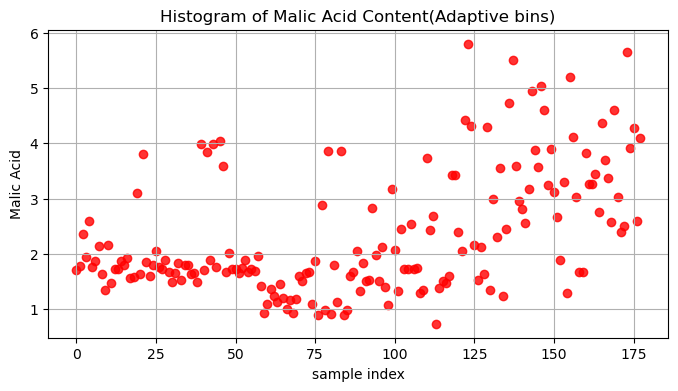

In [28]:
import matplotlib.pyplot

integers = range(len(macid))

plt.figure(figsize=(8,4))
plt.scatter(integers, macid, color= 'red', alpha = 0.8)
plt.title('Histogram of Malic Acid Content(Adaptive bins)')
plt.xlabel('sample index')
plt.ylabel('Malic Acid')
plt.grid(True)
plt.show()

### Z score for outliers
### 3 quartiles
### Boxplot
### Q2 is means

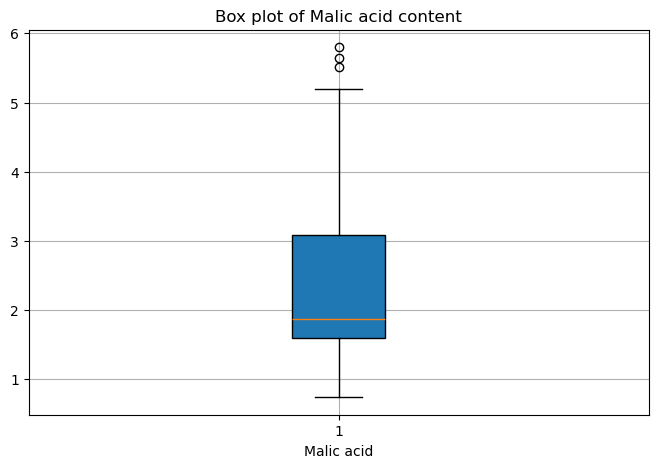

In [29]:
import matplotlib.pyplot as plt

# Plot boxplot
plt.figure(figsize=(8,5))
plt.boxplot(macid,patch_artist=True)
plt.title('Box plot of Malic acid content')
plt.xlabel('Malic acid')
plt.grid(True)
plt.show()

# Day 5

## IQR method for outlier detection

In [30]:
# Inter quantile range method

In [31]:
Q1 = macid.quantile(0.25)
Q3 = macid.quantile(0.75)

IQR = Q3 - Q1

# Outlier Boundaries
lower_bond = Q1-1.5*IQR
upper_bond = Q3 + 1.5*IQR

# Find Outlier
ioutliers = macid[(macid<lower_bond) | (macid > upper_bond)]

print(f"Number of outliers in macid: {len(ioutliers)}")
print(ioutliers)

Number of outliers in macid: 3
123    5.80
137    5.51
173    5.65
Name: malic_acid, dtype: float64


In [32]:
# Z score threshold
from scipy.stats import zscore

z_scores = zscore(macid)

# Set the threshold (3 to 2.5)
threshold = 3
# identify outliers
outliers = macid[np.abs(z_scores) > threshold]

print(f"Number of outliers in macid using z_score > {threshold}: {len(outliers)}")
print(outliers)

Number of outliers in macid using z_score > 3: 1
123    5.8
Name: malic_acid, dtype: float64


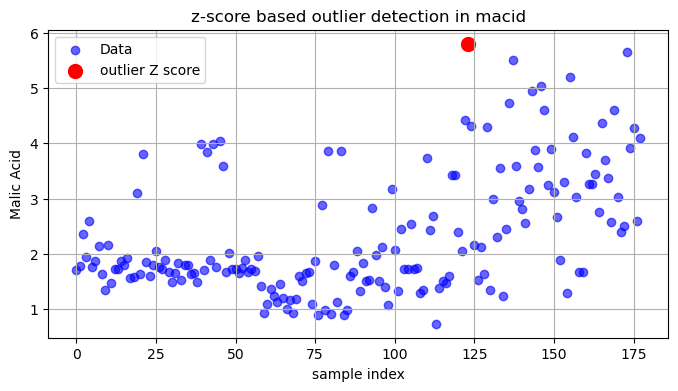

In [33]:
indices = range(len(macid))

plt.figure(figsize=(8,4))
plt.scatter(integers, macid, color= 'blue', label = 'Data',alpha = 0.6)
plt.scatter(outliers.index,outliers, c = 'red', label = 'outlier Z score', s = 100)
plt.title('z-score based outlier detection in macid')
plt.xlabel('sample index')
plt.ylabel('Malic Acid')
plt.legend()
plt.grid(True)
plt.show()

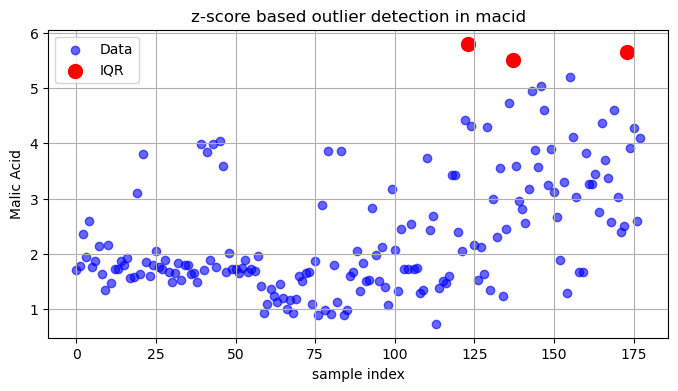

In [34]:
indices = range(len(macid))

plt.figure(figsize=(8,4))
plt.scatter(integers, macid, color= 'blue', label = 'Data',alpha = 0.6)
plt.scatter(ioutliers.index,ioutliers, c = 'red', label = 'IQR', s = 100)
plt.title('z-score based outlier detection in macid')
plt.xlabel('sample index')
plt.ylabel('Malic Acid')
plt.legend()
plt.grid(True)
plt.show()

In [35]:
from scipy.stats import median_abs_deviation

# Compute MAD value
mad = median_abs_deviation(macid)
median = np.median(macid)

# modified z score
modified_z_score  = 0.6745*(macid-median)/mad
# define threshold
threshold = 3.5
outliers = macid[np.abs(modified_z_score) > threshold]

# Output results
print(f"Number of outliers in macid using modified z_score > {threshold}: {len(outliers)}")
print(outliers)

Number of outliers in macid using modified z_score > 3.5: 9
123    5.80
136    4.72
137    5.51
143    4.95
146    5.04
147    4.61
155    5.19
169    4.60
173    5.65
Name: malic_acid, dtype: float64


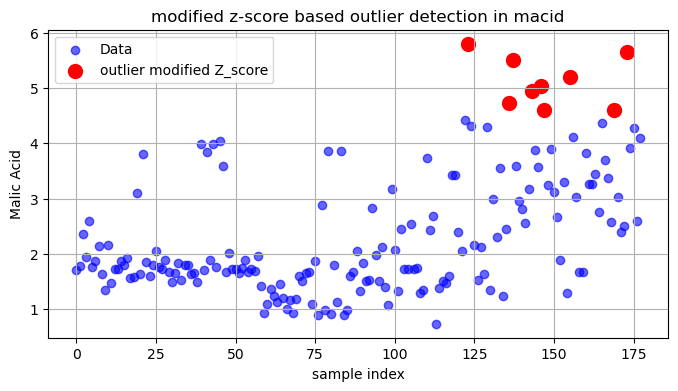

In [36]:
indices = range(len(macid))

plt.figure(figsize=(8,4))
plt.scatter(integers, macid, color= 'blue', label = 'Data',alpha = 0.6)
plt.scatter(outliers.index,outliers, c = 'red', label = 'outlier modified Z_score', s = 100)
plt.title('modified z-score based outlier detection in macid')
plt.xlabel('sample index')
plt.ylabel('Malic Acid')
plt.legend()
plt.grid(True)
plt.show()

# EDA (Exploratory data analysis)

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
books = pd.read_csv("../../data/clean_books.csv")
books.head()

,name,author,rating,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,2019,Childrens


In [39]:
# count values in columns
books.value_counts("genre")

genre
Non Fiction    179
Fiction        131
Childrens       40
Name: count, dtype: int64

In [40]:
books.describe()

,rating,year
count,350.000000,350.000000
mean,4.608571,2013.508571
std,0.226941,3.284711
min,3.300000,2009.000000
25%,4.500000,2010.000000
50%,4.600000,2013.000000
75%,4.800000,2016.000000
max,4.900000,2019.000000


# visulization

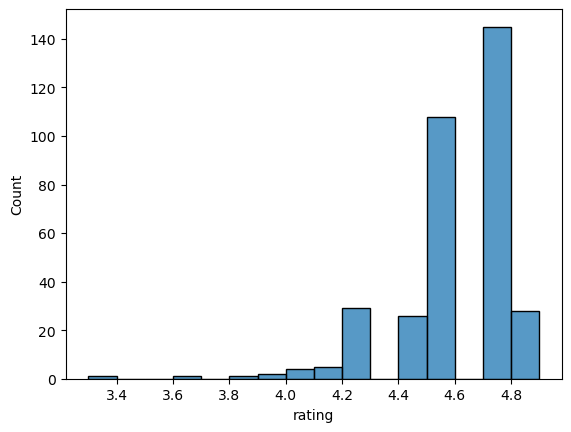

In [41]:
sns.histplot(data=books, x = "rating", binwidth=.1)
plt.show()

In [42]:
books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    350 non-null    object 
 1   author  350 non-null    object 
 2   rating  350 non-null    float64
 3   year    350 non-null    int64  
 4   genre   350 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 13.8+ KB


In [43]:
books.dtypes

name       object
author     object
rating    float64
year        int64
genre      object
dtype: object

In [44]:
books["year"] = books["year"].astype(int)
books.dtypes

name       object
author     object
rating    float64
year        int32
genre      object
dtype: object

In [45]:
# validating catagorical data
books["genre"].isin(["Fiction", "Non Fiction"])

0       True
1       True
2       True
3       True
4      False
       ...  
345     True
346     True
347     True
348     True
349    False
Name: genre, Length: 350, dtype: bool

In [46]:
books.head()

,name,author,rating,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,2019,Childrens


In [47]:
# validating catagorical data
~books["genre"].isin(["Fiction", "Non Fiction"])

0      False
1      False
2      False
3      False
4       True
       ...  
345    False
346    False
347    False
348    False
349     True
Name: genre, Length: 350, dtype: bool

In [48]:
books[books["genre"].isin(["Fiction", "Non Fiction"])].head()

,name,author,rating,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,2017,Fiction
5,A Dance with Dragons (A Song of Ice and Fire),George R. R. Martin,4.4,2011,Fiction


In [49]:
books[~books["genre"].isin(["Fiction", "Non Fiction"])].head()

,name,author,rating,year,genre
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,2019,Childrens
26,Baby Touch and Feel: Animals,DK,4.6,2015,Childrens
36,"Brown Bear, Brown Bear, What Do You See?",Bill Martin Jr.,4.9,2017,Childrens
37,"Cabin Fever (Diary of a Wimpy Kid, Book 6)",Jeff Kinney,4.8,2011,Childrens
53,Dear Zoo: A Lift-the-Flap Book,Rod Campbell,4.8,2015,Childrens


In [50]:
# validating numerical data
books.select_dtypes("number").head()

,rating,year
0,4.7,2016
1,4.6,2011
2,4.7,2018
3,4.7,2017
4,4.8,2019


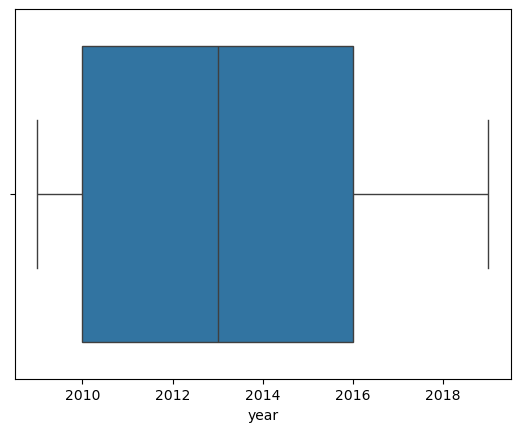

In [51]:
sns.boxplot(data=books, x = "year")
plt.show()

# Exploring groups of data

.groupby() by catagory

In [52]:
books.groupby("genre").mean(numeric_only=True)

,rating,year
genre,,
Childrens,4.780000,2015.075000
Fiction,4.570229,2013.022901
Non Fiction,4.598324,2013.513966


In [53]:
books.select_dtypes("number").agg(["mean","std"])

,rating,year
mean,4.608571,2013.508571
std,0.226941,3.284711


In [54]:
# specification aggregation for columns
books.agg({"rating":["mean","std"],"year":["median"]})

,rating,year
mean,4.608571,NaN
std,0.226941,NaN
median,NaN,2013.0


In [55]:
# Named summary columns
books.groupby("genre").agg(
    mean_rating = ("rating", "mean"),
    std_rating = ("rating", "std"),
    median_year = ("year", "median")
)

,mean_rating,std_rating,median_year
genre,,,
Childrens,4.780000,0.122370,2015.0
Fiction,4.570229,0.281123,2013.0
Non Fiction,4.598324,0.179411,2013.0


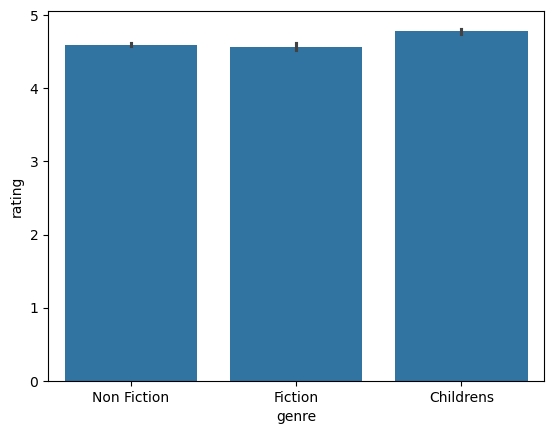

In [56]:
sns.barplot(data = books, x="genre", y = "rating")
plt.show()

## Salaies data set

In [57]:
salaries = pd.read_csv("../../data/salaries_and_fields_cleaned.csv")

# working years to float
salaries["Working_Year"] = salaries['Working_Year'].astype('float64')

# strings to string dtype
salaries['Designation'] = salaries['Designation'].astype('string')
salaries['Experience'] =  salaries['Experience'].astype('string')
salaries['Employment_Status'] = salaries['Employment_Status'].astype('string')
salaries['Employee_Location'] =  salaries['Employee_Location'].astype('string')
salaries['Company_Size'] =  salaries['Company_Size'].astype('string')

#Remote_working_ratio to int64
salaries['Remote_Working_Ratio'] = salaries['Remote_Working_Ratio'].astype('int64')

#salaries_USD to float 64
salaries['Salary_USD'] = salaries['Salary_USD'].astype('float64')

In [58]:
salaries.head()

,Working_Year,Designation,Experience,Employment_Status,Employee_Location,Company_Size,Remote_Working_Ratio,Salary_USD
0,2020.0,Data Scientist,MI,FT,DE,L,0,6352272.0
1,2020.0,Principal Data Scientist,SE,FT,DE,M,100,130000.0
2,2020.0,Lead Data Engineer,SE,FT,NZ,S,50,125000.0
3,2020.0,Data Scientist,SE,FT,US,L,50,120000.0
4,2020.0,Data Scientist,MI,FT,US,M,100,118000.0


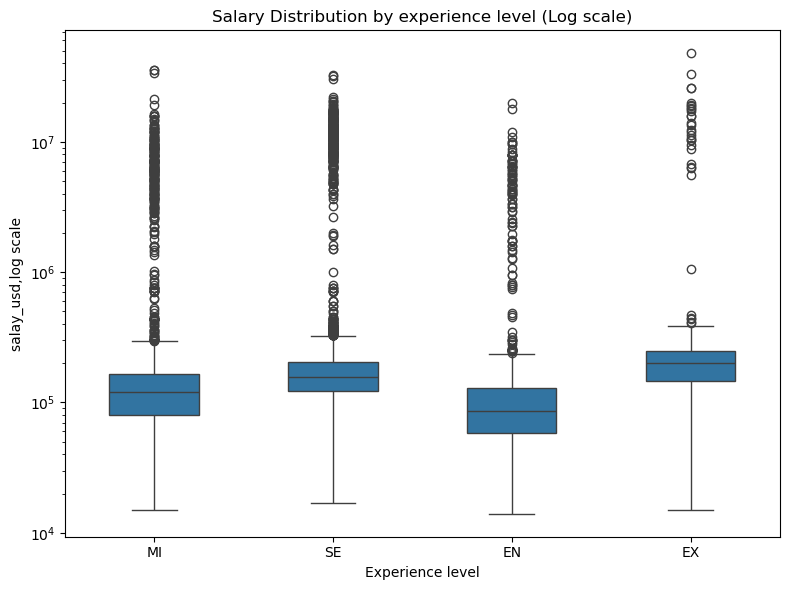

In [59]:
plt.figure(figsize=(8,6))
sns.boxplot(data = salaries,x = "Experience", y = "Salary_USD", width=0.5)
plt.yscale("log")
plt.title("Salary Distribution by experience level (Log scale)")
plt.xlabel("Experience level")
plt.ylabel("salay_usd,log scale")
plt.tight_layout()
plt.show()

In [60]:
salaries.isna().sum()

Working_Year            0
Designation             0
Experience              0
Employment_Status       0
Employee_Location       0
Company_Size            0
Remote_Working_Ratio    0
Salary_USD              0
dtype: int64

In [61]:
np.random.seed(42)
for col in salaries.columns:
    frac_missing = np.random.uniform(0.009, 0.013)
    missing_indices = salaries.sample(frac=frac_missing).index

    salaries.loc[missing_indices,col] = np.nan


In [62]:
salaries.isna().sum()

Working_Year            162
Designation             180
Experience              172
Employment_Status       197
Employee_Location       163
Company_Size            145
Remote_Working_Ratio    176
Salary_USD              169
dtype: int64

In [63]:
# dropping missing values
threshold = len(salaries)*0.01
print(threshold)

154.45000000000002


In [64]:
col_to_drop = salaries.columns[salaries.isna().sum() <= threshold]
col_to_drop

Index(['Company_Size'], dtype='object')

In [65]:
salaries.isna().sum()

Working_Year            162
Designation             180
Experience              172
Employment_Status       197
Employee_Location       163
Company_Size            145
Remote_Working_Ratio    176
Salary_USD              169
dtype: int64

In [66]:
salaries.dropna(subset=col_to_drop,inplace=True)

In [67]:
salaries.isna().sum()

Working_Year            160
Designation             178
Experience              171
Employment_Status       193
Employee_Location       160
Company_Size              0
Remote_Working_Ratio    173
Salary_USD              168
dtype: int64

In [68]:
cols_with_missing_values = salaries.columns[salaries.isna().sum()>0]
cols_with_missing_values

Index(['Working_Year', 'Designation', 'Experience', 'Employment_Status',
       'Employee_Location', 'Remote_Working_Ratio', 'Salary_USD'],
      dtype='object')

In [69]:
for col in cols_with_missing_values[:-1]:
    salaries[col] = salaries[col].fillna(salaries[col].mode()[0])

In [70]:
salaries.isna().sum()

Working_Year              0
Designation               0
Experience                0
Employment_Status         0
Employee_Location         0
Company_Size              0
Remote_Working_Ratio      0
Salary_USD              168
dtype: int64

In [71]:
salary_dict = salaries.groupby("Experience")["Salary_USD"].median().to_dict()
salary_dict

{'EN': 85128.0, 'EX': 200000.0, 'MI': 120000.0, 'SE': 156426.5}

In [72]:
salaries["Salary_USD"] = salaries["Salary_USD"].fillna(salaries["Experience"].map(salary_dict))

In [73]:
salaries.isna().sum()

Working_Year            0
Designation             0
Experience              0
Employment_Status       0
Employee_Location       0
Company_Size            0
Remote_Working_Ratio    0
Salary_USD              0
dtype: int64

In [74]:
salaries["Designation"].value_counts()

Designation
Data Engineer                      3399
Data Scientist                     3097
Data Analyst                       2242
Machine Learning Engineer          1547
Research Scientist                  481
                                   ... 
Staff Machine Learning Engineer       1
Power BI Developer                    1
CRM Data Analyst                      1
Quantitative Research Analyst         1
Data Analytics Associate              1
Name: count, Length: 155, dtype: Int64

In [75]:
top_5_designations = salaries["Designation"].value_counts().nlargest(5)

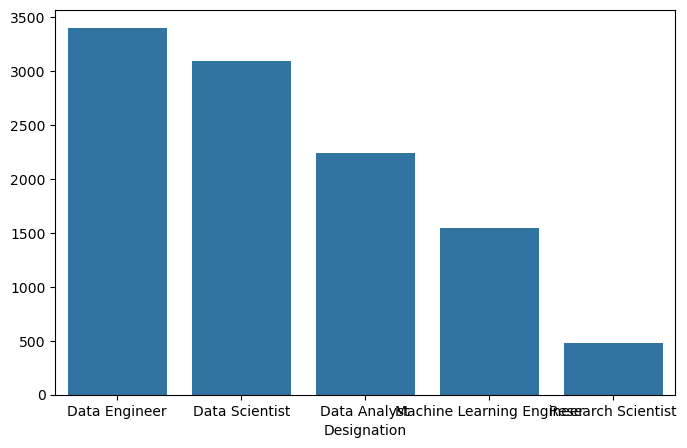

In [76]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x=top_5_designations.index,
    y=top_5_designations.values
)

plt.show()

In [77]:
salaries["Designation"].str.contains("Machine Learning|AI")

0        False
1        False
2        False
3        False
4        False
         ...  
15440    False
15441    False
15442    False
15443    False
15444    False
Name: Designation, Length: 15300, dtype: boolean

In [78]:
salaries["Designation"].str.contains("")

0        True
1        True
2        True
3        True
4        True
         ... 
15440    True
15441    True
15442    True
15443    True
15444    True
Name: Designation, Length: 15300, dtype: boolean

In [86]:
job_catagories = ["Data Science", "Data Analytics", "Data Engineering","Machine Learning", "Managerial","Consultant"]

data_science = "Data Scientist|NLP"
data_analyst = "Analyst|Analystics"
data_engineer = "Data Engineer|ETL|Architect|Infrastructure"
ml_engineer = "Machine Learning|ML|Big Data| AI"
manager = "Manager|Head|Director|Lead|Principal|Staff"
consultant = "Consultant|Freelance"

conditions=[
    (salaries["Designation"].str.contains(data_science)),
    (salaries["Designation"].str.contains(data_analyst)),
    (salaries["Designation"].str.contains(data_engineer)),
    (salaries["Designation"].str.contains(ml_engineer)),
    (salaries["Designation"].str.contains(manager)),
    (salaries["Designation"].str.contains(consultant))
]

In [87]:
salaries["job_catagory"] = np.select(conditions, job_catagories, default="other")

In [88]:
salaries.head()

,Working_Year,Designation,Experience,Employment_Status,Employee_Location,Company_Size,Remote_Working_Ratio,Salary_USD,job_catagory
0,2020.0,Data Scientist,MI,FT,DE,L,0.0,6352272.0,Data Science
1,2020.0,Principal Data Scientist,SE,FT,DE,M,100.0,130000.0,Data Science
2,2020.0,Lead Data Engineer,SE,FT,US,S,50.0,125000.0,Data Engineering
3,2020.0,Data Scientist,SE,FT,US,L,50.0,120000.0,Data Science
4,2020.0,Data Scientist,MI,FT,US,M,100.0,118000.0,Data Science


In [90]:
salaries["job_catagory"].value_counts()

job_catagory
Data Engineering    3947
Data Science        3166
other               2794
Data Analytics      2712
Machine Learning    1972
Managerial           614
Consultant            95
Name: count, dtype: int64

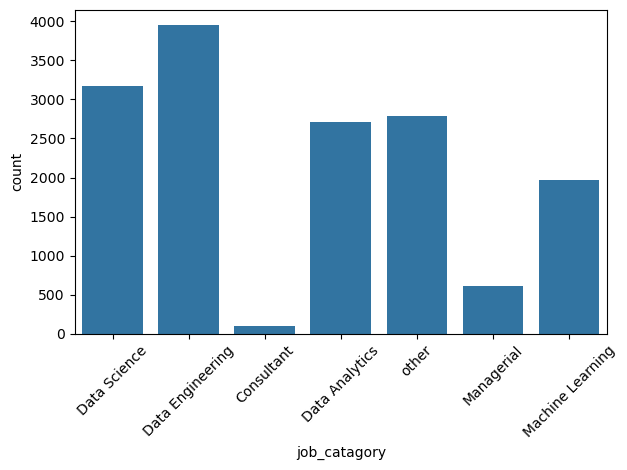

In [91]:
sns.countplot(data = salaries, x="job_catagory")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [94]:
salaries["std_dev"] = salaries.groupby("Experience")["Salary_USD"].transform(lambda x:x.std())

In [95]:
salaries.head()

,Working_Year,Designation,Experience,Employment_Status,Employee_Location,Company_Size,Remote_Working_Ratio,Salary_USD,job_catagory,std_dev
0,2020.0,Data Scientist,MI,FT,DE,L,0.0,6352272.0,Data Science,1.988059e+06
1,2020.0,Principal Data Scientist,SE,FT,DE,M,100.0,130000.0,Data Science,1.949743e+06
2,2020.0,Lead Data Engineer,SE,FT,US,S,50.0,125000.0,Data Engineering,1.949743e+06
3,2020.0,Data Scientist,SE,FT,US,L,50.0,120000.0,Data Science,1.949743e+06
4,2020.0,Data Scientist,MI,FT,US,M,100.0,118000.0,Data Science,1.988059e+06


In [97]:
salaries["median_by_com_size"] = salaries.groupby("Company_Size")["Salary_USD"].transform(lambda x:x.median())

In [98]:
salaries.head()

,Working_Year,Designation,Experience,Employment_Status,Employee_Location,Company_Size,Remote_Working_Ratio,Salary_USD,job_catagory,std_dev,median_by_com_size
0,2020.0,Data Scientist,MI,FT,DE,L,0.0,6352272.0,Data Science,1.988059e+06,150000.0
1,2020.0,Principal Data Scientist,SE,FT,DE,M,100.0,130000.0,Data Science,1.949743e+06,145000.0
2,2020.0,Lead Data Engineer,SE,FT,US,S,50.0,125000.0,Data Engineering,1.949743e+06,120000.0
3,2020.0,Data Scientist,SE,FT,US,L,50.0,120000.0,Data Science,1.949743e+06,150000.0
4,2020.0,Data Scientist,MI,FT,US,M,100.0,118000.0,Data Science,1.988059e+06,145000.0


In [100]:
salaries[["Company_Size","median_by_com_size"]].value_counts()

Company_Size  median_by_com_size
M             145000.0              13869
L             150000.0               1170
S             120000.0                261
Name: count, dtype: int64